In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

In [2]:
df = pd.read_csv("movie_multilabel.csv")
df.head()


,Duration_Min,Violence_Level,Comedy_Scenes,Budget_Million,Star_Power,Action,Comedy,Romance
0,120,High,Low,80,5,1,0,0
1,90,Low,High,40,3,0,1,1
2,150,High,Medium,100,4,1,0,1
3,110,Low,High,50,3,0,1,0
4,140,Medium,Low,70,4,1,0,0


In [3]:
le = LabelEncoder()

df["Violence_Level"] = le.fit_transform(df["Violence_Level"])
df["Comedy_Scenes"] = le.fit_transform(df["Comedy_Scenes"])



'''
What Happens Internally
   Low  0
Medium  1
  High  2
(Exact order does not matter for ANN)
'''

In [4]:
num_labels = 3  # Action, Comedy, Romance

X = df.iloc[:, :-num_labels]#df.iloc[:, :-3]
y = df.iloc[:, -num_labels:]#df.iloc[:, -3:]



'''
Last 3 columns are outputs
Remaining columns are inputs
This works even if columns increase later
'''

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


'''
80% movies for training
20% movies for testing
Prevents memorization
'''

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
input_features = X_train_scaled.shape[1]
#Gets the number of input columns/features in your training data.
num_labels = y_train.shape[1]
#Gets the number of movie genres to predict, such as Action, Comedy, and Romance.

model = nn.Sequential(nn.Linear(input_features, 10), nn.ReLU(),nn.Linear(10, num_labels))
#model = nn.Sequential(
#Creates the neural network by stacking layers in order. No custom class or forward() method is needed.

#nn.Linear(input_features, 10),
#First layer: receives all input features and produces 10 values.

#nn.ReLU(),
#Applies ReLU activation. It changes negative values to 0 and keeps positive values, helping the network learn patterns.

#nn.Linear(10, num_labels)
#Final layer: converts the 10 values into one prediction score for each genre.

criterion = nn.BCEWithLogitsLoss()
#Sets the loss function. This is appropriate because a movie may belong to multiple genres at the same time.

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
#Creates the Adam optimizer, which adjusts the model’s weights while training. 0.001 is its learning rate.

print(model)
#- Displays the structure of the neural network.

Sequential(
  (0): Linear(in_features=5, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=3, bias=True)
)


### PyTorch ANN architecture
The model has five input features, a fully connected hidden layer with 10 ReLU neurons, and three output logits for Action, Comedy, and Romance.

`BCEWithLogitsLoss` combines sigmoid activation with binary cross-entropy in a numerically stable way. 
During prediction, apply `torch.sigmoid()` to the logits to get one independent probability per genre.

For five inputs, the first layer has `(5 X 10) + 10 = 60` parameters. The output layer has `(10 X 3) + 3 = 33` parameters. 
The network therefore has 93 trainable parameters.

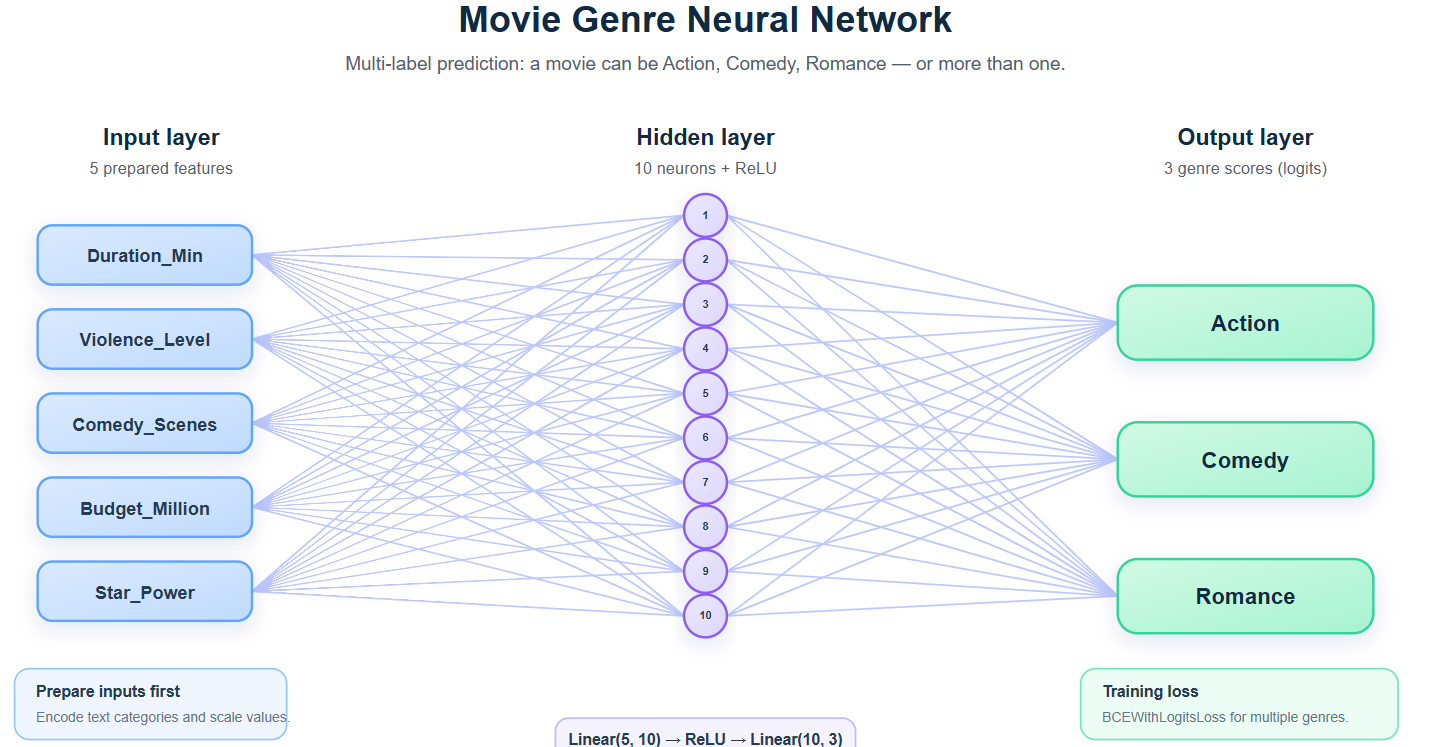

In [8]:
input_features = X_train_scaled.shape[1]   # 5 input columns
num_labels = y_train.shape[1]              # Action, Comedy, Romance

model = nn.Sequential(
    nn.Linear(input_features, 16),  # Hidden layer 1: 5 → 16
    nn.ReLU(),

    nn.Linear(16, 12),              # Hidden layer 2: 16 → 12
    nn.ReLU(),

    nn.Linear(12, 8),               # Hidden layer 3: 12 → 8
    nn.ReLU(),

    nn.Linear(8, 4),                # Hidden layer 4: 8 → 4
    nn.ReLU(),

    nn.Linear(4, num_labels)        # Output layer: 4 → 3 genres
)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

Sequential(
  (0): Linear(in_features=5, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=12, bias=True)
  (3): ReLU()
  (4): Linear(in_features=12, out_features=8, bias=True)
  (5): ReLU()
  (6): Linear(in_features=8, out_features=4, bias=True)
  (7): ReLU()
  (8): Linear(in_features=4, out_features=3, bias=True)
)


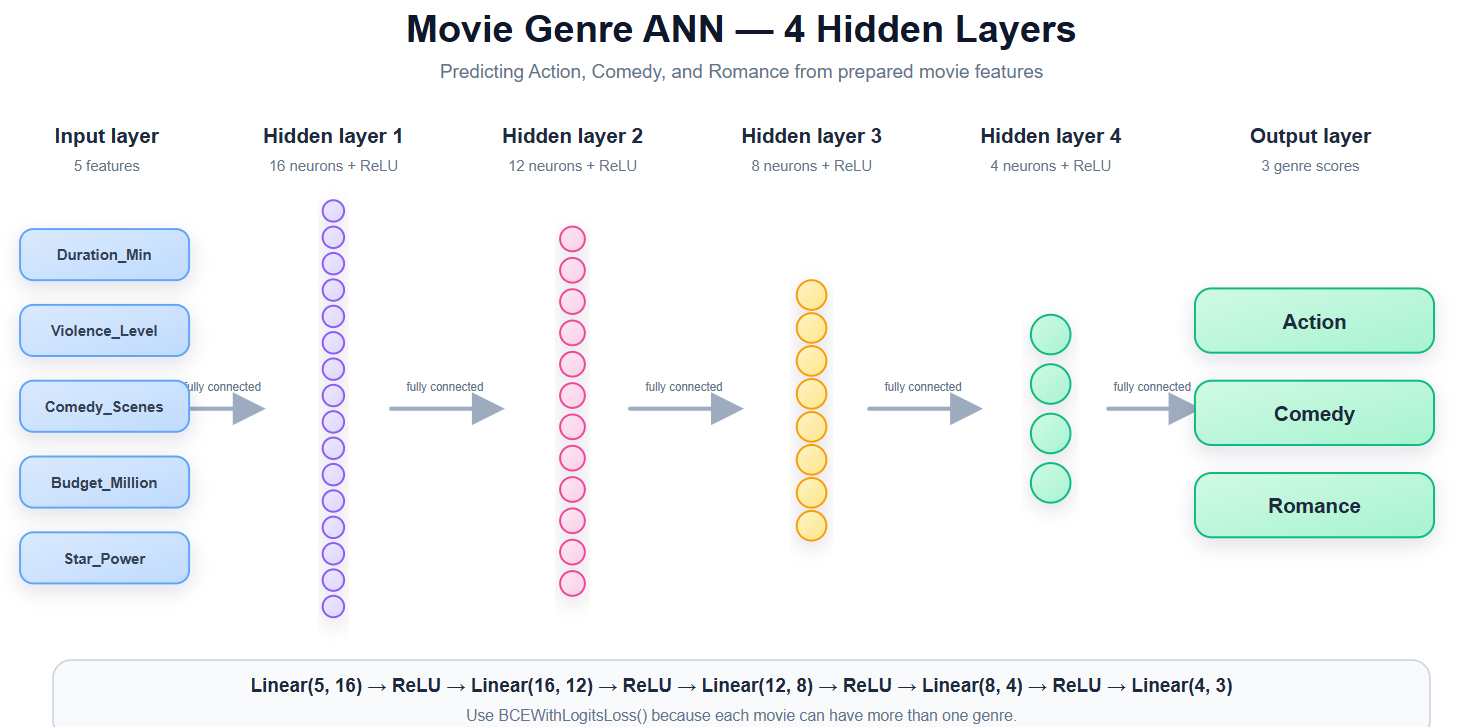

###PyTorch ANN architecture
The model has five input features, four fully connected hidden layers with 16, 12, 8, and 4 ReLU neurons, and three output logits for Action, Comedy, and Romance.
BCEWithLogitsLoss combines sigmoid activation with binary cross-entropy in a numerically stable way. During prediction, apply torch.sigmoid() to the logits to get one independent probability per genre.
Parameter count:
- First hidden layer, 5 → 16: (5 × 16) + 16 = 96
- Second hidden layer, 16 → 12: (16 × 12) + 12 = 204
- Third hidden layer, 12 → 8: (12 × 8) + 8 = 104
- Fourth hidden layer, 8 → 4: (8 × 4) + 4 = 36
- Output layer, 4 → 3: (4 × 3) + 3 = 15
The network therefore has:
96 + 204 + 104 + 36 + 15 = 455 trainable parameters

In [15]:
# Change training data into PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
#A tensor is PyTorch’s version of an array.

# Put inputs and answers together
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
#TensorDataset keeps each movie’s features together with its genre labels.

# Give the model 2 movies at a time, in random order
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
#batch_size=2 means the model learns from two movies at once.

epochs = 10
#An epoch means the model has seen all training rows once.
model.train()

for epoch in range(epochs):

    total_loss = 0
    
    # Train using one small batch at a time
    for features, labels in train_loader:

        optimizer.zero_grad()           # Clear old gradients
        predictions = model(features)   # Model predicts genres
        loss = criterion(predictions, labels)  # Compare prediction with correct genres
        #loss shows how wrong the predictions are; lower is better.

        loss.backward()                 # Calculate how to improve weights
        #backward() finds what should change, and step() makes the change.
        
        optimizer.step()                # Update the weights

        total_loss = total_loss + loss.item()       # Save this batch's loss

    # Print progress after every 50 rounds
    if (epoch + 1) % 2 == 0:
        average_loss = total_loss / len(train_loader)
        print(f"Epoch {epoch + 1}/{epochs} - Loss: {average_loss:.4f}")

Epoch 2/10 - Loss: 0.3258
Epoch 4/10 - Loss: 0.3201
Epoch 6/10 - Loss: 0.3112
Epoch 8/10 - Loss: 0.3071
Epoch 10/10 - Loss: 0.3001


Training process — single hidden layer
The model sees the complete movie training data 100 times:
epochs = 100
For each batch, the movie features pass through the network:
5 input features → 10 ReLU neurons → 3 genre logits
The model may learn patterns such as:
Higher violence may increase the Action probability.
More comedy scenes may increase the Comedy probability.
A combination of features may increase the Romance probability.
What happens internally?
With batch_size=2, the model:
1. Looks at 2 movie records.
2. Sends their 5 features to the 10-neuron hidden layer.
3. Produces 3 scores: Action, Comedy, and Romance.
4. Calculates the error using BCEWithLogitsLoss.
5. Updates its 93 trainable parameters.
6. Moves to the next batch.
If the training data has 10 rows:
Batch 1 → 2 movie records
Batch 2 → 2 movie records
Batch 3 → 2 movie records
Batch 4 → 2 movie records
Batch 5 → 2 movie records
After all 5 batches, one epoch is complete.
5 batches per epoch × 100 epochs = 500 weight updates
Because shuffle=True, the movie rows are mixed into different batches each epoch.

Training process - Multi Hidden Layer
The model sees the complete movie training data 100 times because:
epochs = 100
In each batch, the movie features pass through the network:
5 inputs → 16 → 12 → 8 → 4 → 3 genre logits
The model can learn patterns such as:
Higher violence may increase the Action probability.
More comedy scenes may increase the Comedy probability.
A combination of duration, violence, budget, and star power may affect Romance probability.
What happens internally?
Your training data is split into small groups called batches.
Because batch_size=2, the model:
1. Looks at 2 movie records.
2. Predicts Action, Comedy, and Romance for both records.
3. Calculates the error using BCEWithLogitsLoss.
4. Uses the error to update its 455 trainable parameters.
5. Moves to the next batch.
If the training set has 10 rows, one epoch contains 5 batches:
Batch 1 → 2 movie records
Batch 2 → 2 movie records
Batch 3 → 2 movie records
Batch 4 → 2 movie records
Batch 5 → 2 movie records
After the 5 batches, one epoch is complete.
Since there are 100 epochs:
5 batches per epoch × 100 epochs = 500 weight updates
Because shuffle=True, the rows are mixed into different batches each epoch.

In [16]:
# Convert test data to PyTorch tensors
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(
    y_test.to_numpy(dtype=np.float32),
    dtype=torch.float32
)

# Switch model to evaluation mode
model.eval()

# Do not calculate gradients during testing
with torch.inference_mode():

    test_logits = model(X_test_tensor)

    # Calculate test loss
    test_loss = criterion(test_logits, y_test_tensor).item()

    # Convert logits into probabilities from 0 to 1
    test_probabilities = torch.sigmoid(test_logits)

    # Genre is predicted when probability is at least 0.5
    test_predictions = (test_probabilities >= 0.5).float()

    # Compare every predicted genre label with the real label
    label_accuracy = (
        (test_predictions == y_test_tensor)
        .float()
        .mean()
        .item()
    )

print(f"Test loss: {test_loss:.4f}")
print(f"Label accuracy: {label_accuracy:.2f}")
#label_accuracy measures each individual genre label. For example, it checks whether Action, Comedy, and Romance predictions are each correct.

Test loss: 0.3162
Label accuracy: 0.83


In [ ]:
# Predict genres for a new movie
new_movie = pd.DataFrame({
    "Duration_Min": [135],
    "Violence_Level": [2],  # High
    "Comedy_Scenes": [1],   # Medium
    "Budget_Million": [85],
    "Star_Power": [4]
})

new_movie_scaled = scaler.transform(new_movie)
new_movie_tensor = torch.tensor(new_movie_scaled, dtype=torch.float32)

model.eval()#model.eval() switches the model into testing/prediction mode.

with torch.inference_mode():#torch.inference_mode() stops PyTorch from calculating gradients, making prediction faster and using less memory.
    prediction = torch.sigmoid(model(new_movie_tensor)).numpy()

#model(new_movie_tensor) gives raw output scores, called logits.
#torch.sigmoid(...) changes each logit into a probability between 0 and 1.
#.cpu().numpy() converts the PyTorch tensor into a NumPy array. .cpu() is needed if the model uses a GPU.    

print(prediction)

[[0.9527033  0.02246056 0.02298346]]


In [12]:
# Convert probabilities to final labels
final_output = (prediction >= 0.5).astype(int)
print(final_output)

# [1, 0, 0] means Action = yes, Comedy = no, Romance = no

[[1 0 0]]


In [13]:
# Save the PyTorch model weights
torch.save(model.state_dict(), "movie_ann_model.pt")

In [14]:
import joblib
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']